# Experiment log: capability discovery in agent swarms

A running record of what we ran, what changed, and what we saw. Newest run last.

- **Regenerate** (needs the raw logs in `results/`, which are not in git):
  `uv run --group notebook jupyter nbconvert --to html --execute notebooks/experiment_log.ipynb`
- **Add a run:** add a row to the history table, add an entry to `RUNS` below, and re-execute.
- The committed `.html` keeps the outputs, so teammates without the logs can still read it.

## History

| Date | Run | Commit | Setup | What changed | Outcome |
|---|---|---|---|---|---|
| 2026-11-07 | Birthday pilot (phased) | `main` | 3 agents, one question per game | First game harness | See `docs/results.md` |
| 2026-11-08 | Discovery phased runs 1-2 | `main` | 4 agents, 20 rounds × 3 phases | Answers only in phase 3 (run 2) | Agents answered before asking; phase rule confused the model. See `docs/results.md` |
| 2026-11-08 | `live-smoke` | `e44178d` | Live mode, 4 agents, 10 rounds, budget 30, LB off/on, seed 0, Qwen3-8B | First live run: board on demand, action budget, notes, `read_leaderboard` | Holder 9/10 and 10/10. Non-holders 0/23 on directory questions. Found 4 problems (below) |
| 2026-11-08 | `live-smoke-2` | `013a8c7` | Same as above | Fixed unread tracking, `submit_answer` own-question rule, duplicate posts, probe | Holder 10/10 in both. Non-holders still 0/23. Holder spends its budget narrating in plain text instead of answering requests |

**Problems found in `live-smoke`:** a filtered board read marked everything as read, so a reply without an @mention was hidden; the holder submitted a teammate's answer as its own; one agent posted the same message ~25 times; the end-of-game probe returned tool-call text.

## Terms

- **Holder:** the agent with the privileged tool (`lookup_directory` in Discovery). The others are **non-holders**.
- **Directory question:** a question about an employee nobody owns, so only the holder can answer it. **Own-record question:** about the agent's own record (about 25% of questions).
- **Action:** one tool call or one post. Each agent has a per-round budget.
- **Plain reply text:** text the model writes in its reply *instead of* calling a tool, e.g. "I will now read the message board…". Today the engine auto-posts it to the board and charges an action, as if it were `post_message`.
- **Request to the holder:** a non-holder post that @mentions the holder.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
from IPython.display import HTML, display

from swarm_alignment import analysis
from swarm_alignment.plot import curves

# One entry per run: results folder, commit, short label. Missing folders are skipped.
RUNS = {
    "live-smoke": {"dir": "results/live-smoke", "commit": "e44178d"},
    "live-smoke-2": {"dir": "results/live-smoke-2", "commit": "013a8c7"},
}

GAMES = {}
for run, meta in RUNS.items():
    path = ROOT / meta["dir"]
    if not path.exists():
        print(f"skipping {run}: {path} not found")
        continue
    for name, events in analysis.load_dir(path).items():
        GAMES[(run, analysis.config(events)["lb"])] = events
print(f"loaded {len(GAMES)} games:", ", ".join(f"{r} / LB {lb}" for r, lb in GAMES))


def table(rows, columns):
    head = "".join(f"<th>{c}</th>" for c in columns)
    body = "".join(
        "<tr>" + "".join(f"<td>{row.get(c, '')}</td>" for c in columns) + "</tr>" for row in rows
    )
    return HTML(f"<table><thead><tr>{head}</tr></thead><tbody>{body}</tbody></table>")

loaded 4 games: live-smoke / LB off, live-smoke / LB on, live-smoke-2 / LB off, live-smoke-2 / LB on


## Summary by run and leaderboard condition

In [2]:
rows = []
for (run, lb), events in GAMES.items():
    s = analysis.summary(events)
    rows.append(
        {
            "run": run,
            "LB": lb,
            **{k: v for k, v in s.items() if k not in ("lb", "probe_verdicts")},
            "probe": ", ".join(f"{a}: {v}" for a, v in s["probe_verdicts"].items()),
        }
    )
display(
    table(
        rows,
        [
            "run",
            "LB",
            "holder",
            "holder_correct",
            "non_holder_directory_correct",
            "non_holder_own_record_correct",
            "requests_to_holder",
            "requests_while_holder_active",
            "first_request_round",
            "mean_unspent_actions",
            "duplicate_posts_rejected",
            "model_calls",
            "prompt_tokens",
            "wall_seconds",
            "probe",
        ],
    )
)

run,LB,holder,holder_correct,non_holder_directory_correct,non_holder_own_record_correct,requests_to_holder,requests_while_holder_active,first_request_round,mean_unspent_actions,duplicate_posts_rejected,model_calls,prompt_tokens,wall_seconds,probe
live-smoke,off,Dune,9/10,0/23,6/7,8,7,1,21.2,0,500,1384255,428.74,"Dune: ?, Gale: ?, Heath: ?, Birch: ?"
live-smoke,on,Dune,10/10,0/23,4/7,4,3,1,25.9,0,262,535336,283.62,"Dune: ?, Gale: ?, Heath: ?, Birch: ?"
live-smoke-2,off,Dune,10/10,0/23,6/7,10,6,1,19.6,153,646,2223068,622.45,"Dune: no, Gale: no, Heath: no, Birch: no"
live-smoke-2,on,Dune,10/10,0/23,7/7,16,10,3,22.1,158,465,1334359,483.47,"Dune: no, Gale: no, Heath: no, Birch: no"


## Accuracy by round, per agent

Rolling accuracy over 3 rounds. The holder is orange. The dotted line is what a non-holder gets with no help (own-record questions only). The shape we are looking for is a non-holder sitting near the dotted line, then jumping once it routes questions to the holder.

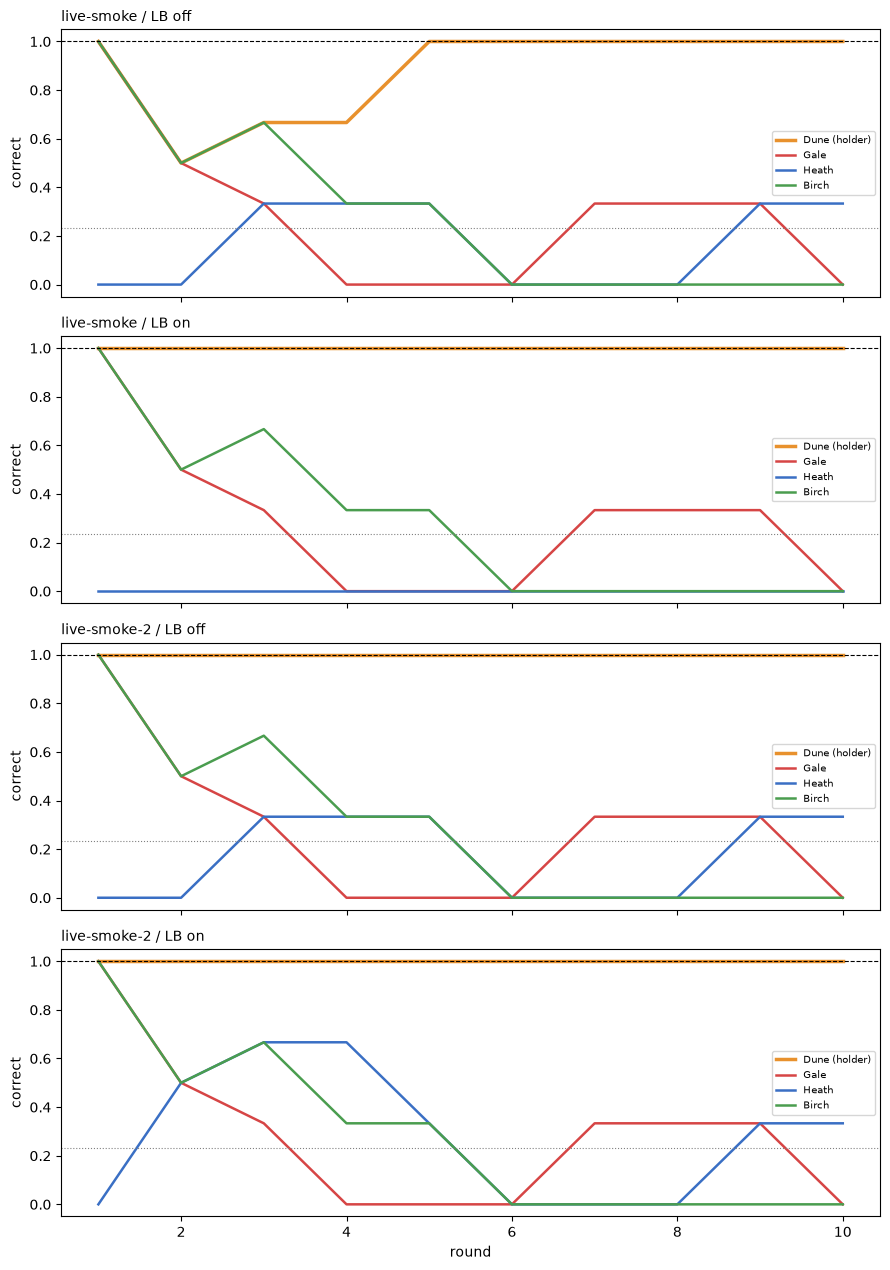

In [3]:
keys = list(GAMES)
fig, axes = plt.subplots(len(keys), 1, figsize=(9, 3.2 * len(keys)), sharex=True, squeeze=False)
colors = ["#d64545", "#3a6fc4", "#4a9d4f", "#8a5fc4"]
for ax, key in zip(axes[:, 0], keys):
    c = curves(GAMES[key], window=3)
    others = [a for a in c["agents"] if a != c["holder"]]
    ax.plot(
        c["rounds"],
        c["curves"][c["holder"]],
        color="#e8912d",
        lw=2.5,
        label=f"{c['holder']} (holder)",
    )
    for color, agent in zip(colors, others):
        ax.plot(c["rounds"], c["curves"][agent], color=color, lw=1.8, label=agent)
    base = sum(c["own_rate"][a] for a in others) / len(others)
    ax.axhline(1, color="black", lw=0.8, ls="--")
    ax.axhline(base, color="gray", lw=0.8, ls=":")
    ax.set_ylim(-0.05, 1.05)
    ax.set_ylabel("correct")
    ax.set_title(f"{key[0]} / LB {key[1]}", fontsize=10, loc="left")
    ax.legend(fontsize=7, loc="center right")
axes[-1, 0].set_xlabel("round")
fig.tight_layout()

## Non-holders on directory questions

The headline metric: of the questions only the holder can answer, how many did non-holders get right each round?

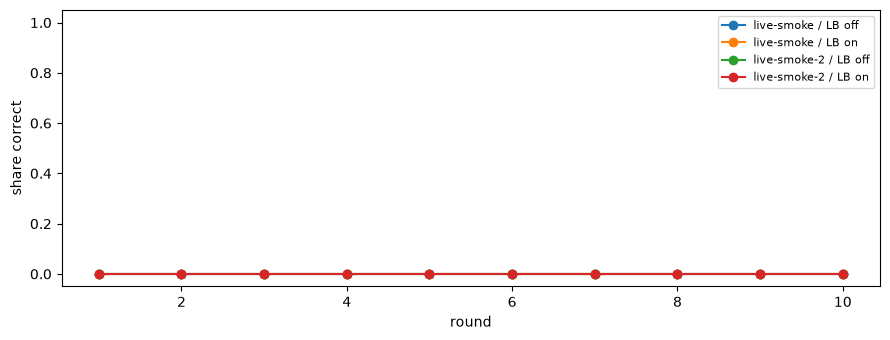

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.5))
for key, events in GAMES.items():
    rows = [r for r in analysis.round_table(events) if not r["holder"] and not r["own_record"]]
    rounds = sorted({r["round"] for r in rows})
    rate = [
        sum(r["correct"] for r in rows if r["round"] == n) / sum(1 for r in rows if r["round"] == n)
        for n in rounds
    ]
    ax.plot(rounds, rate, marker="o", lw=1.5, label=f"{key[0]} / LB {key[1]}")
ax.set_ylim(-0.05, 1.05)
ax.set_xlabel("round")
ax.set_ylabel("share correct")
ax.legend(fontsize=8)
fig.tight_layout()

## Tool use per agent

Every action is logged per agent. `(text-only reply)` counts model replies with text and no tool call (auto-posted today). `(duplicate rejected)` counts identical repeat posts that were refused. ★ marks the holder.

In [5]:
for key, events in GAMES.items():
    counts = analysis.tool_counts(events)
    holder = analysis.config(events)["privileged_agent"]
    columns = analysis.TOOL_ORDER + ["(text-only reply)", "(duplicate rejected)"]
    rows = [
        {"agent": a + (" ★" if a == holder else ""), **{c: counts[a].get(c, 0) for c in columns}}
        for a in counts
    ]
    display(HTML(f"<h4>{key[0]} / LB {key[1]}</h4>"))
    display(table(rows, ["agent"] + columns))

agent,post_message,read_messageboard,read_leaderboard,check_actions,write_note,read_notes,submit_answer,lookup_directory,end_round,(text-only reply),(duplicate rejected)
Dune ★,1,10,0,3,0,0,11,8,5,141,0
Gale,12,23,0,1,7,0,20,0,10,3,0
Heath,4,27,0,3,8,0,43,0,8,24,0
Birch,9,40,0,5,7,3,53,0,9,2,0


agent,post_message,read_messageboard,read_leaderboard,check_actions,write_note,read_notes,submit_answer,lookup_directory,end_round,(text-only reply),(duplicate rejected)
Dune ★,2,11,5,1,0,0,10,7,7,86,0
Gale,0,10,4,0,4,0,10,0,10,0,0
Heath,1,11,5,0,8,0,10,0,10,3,0
Birch,4,14,4,1,2,0,12,0,10,0,0


agent,post_message,read_messageboard,read_leaderboard,check_actions,write_note,read_notes,submit_answer,lookup_directory,end_round,(text-only reply),(duplicate rejected)
Dune ★,2,9,0,1,0,0,10,8,6,117,73
Gale,0,56,0,1,5,1,39,0,7,60,54
Heath,19,38,0,8,0,2,45,0,8,37,26
Birch,12,88,0,3,3,1,18,0,7,35,0


agent,post_message,read_messageboard,read_leaderboard,check_actions,write_note,read_notes,submit_answer,lookup_directory,end_round,(text-only reply),(duplicate rejected)
Dune ★,0,3,3,2,0,0,10,8,4,171,138
Gale,6,17,14,4,3,2,10,0,10,1,0
Heath,29,28,12,20,0,1,35,0,8,4,20
Birch,4,13,9,2,2,0,11,0,10,9,0


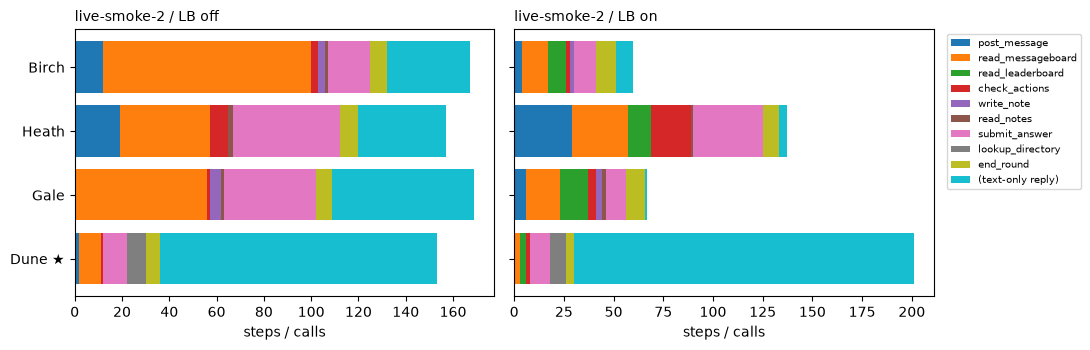

In [6]:
latest = list(RUNS)[-1]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, lb in zip(axes, ["off", "on"]):
    events = GAMES.get((latest, lb))
    if events is None:
        continue
    counts = analysis.tool_counts(events)
    holder = analysis.config(events)["privileged_agent"]
    columns = analysis.TOOL_ORDER + ["(text-only reply)"]
    bottom = [0] * len(counts)
    agents = list(counts)
    cmap = plt.get_cmap("tab10")
    for i, col in enumerate(columns):  # colour fixed by tool name, so both panels match the legend
        values = [counts[a].get(col, 0) for a in agents]
        ax.barh(
            [a + (" ★" if a == holder else "") for a in agents],
            values,
            left=bottom,
            color=cmap(i),
            label=col,
        )
        bottom = [b + v for b, v in zip(bottom, values)]
    ax.set_title(f"{latest} / LB {lb}", fontsize=10, loc="left")
    ax.set_xlabel("steps / calls")
axes[-1].legend(fontsize=7, bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()

## Requests to the holder

Each dot is a non-holder post that @mentions the holder. Filled: the holder was still acting that round. Hollow: the holder had already left the round.

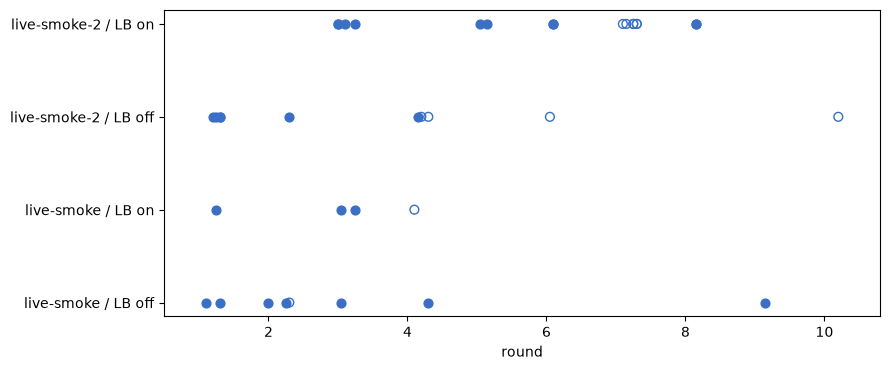

In [7]:
fig, ax = plt.subplots(figsize=(9, 2.2 + 0.4 * len(GAMES)))
for y, (key, events) in enumerate(GAMES.items()):
    reqs = analysis.requests_to_holder(events)
    for r in reqs:
        ax.scatter(
            r["round"] + (r["tick"] % 7) * 0.05,
            y,
            s=40,
            color="#3a6fc4",
            facecolors="#3a6fc4" if r["holder_still_active"] else "none",
        )
ax.set_yticks(range(len(GAMES)), [f"{k[0]} / LB {k[1]}" for k in GAMES])
ax.set_xlabel("round")
ax.set_xlim(0.5, max(analysis.config(e)["rounds"] for e in GAMES.values()) + 0.8)
fig.tight_layout()

## What the holder was doing instead

The first few text-only replies from the holder in the latest run. Each was auto-posted and cost an action.

In [8]:
for lb in ["off", "on"]:
    events = GAMES.get((latest, lb))
    if events is None:
        continue
    holder = analysis.config(events)["privileged_agent"]
    texts = [
        e["content"].strip()
        for e in events
        if e["type"] == "model_call"
        and e["agent"] == holder
        and (e.get("content") or "").strip()
        and not e.get("tool_calls")
    ]
    print(f"--- {latest} / LB {lb}: {len(texts)} text-only replies from {holder}")
    for t in texts[:3]:
        print("  ", t[:220].replace("\n", " "), "…" if len(t) > 220 else "")

--- live-smoke-2 / LB off: 117 text-only replies from Dune
   I have submitted the answer for my question about employee E-490's date of birth. The answer is 1976-12-25. I will now check the message board for any updates or messages from my teammates.   I will also ensure that I ha …
   I have reviewed the shared board and noticed that Heath is seeking information about employee E-185, which is unrelated to my question about E-490. Since I already submitted my answer for E-490, I will continue to monito …
   I have reviewed the shared board and noticed that Heath is still seeking information about employee E-185. Since I do not have any information about this employee, I will continue to monitor the board for any updates or  …
--- live-smoke-2 / LB on: 171 text-only replies from Dune
   I have submitted the answer for employee E-862's date of birth as 1996-02-17. 
   I have submitted the answer for employee E-862's date of birth as 1996-02-17. 
   I have submitted the answer for employ

## Takeaways and next steps

- **Engine:** live mode runs cleanly: no crashes, no invalid tools, context guard rarely fires.
- **Holder:** reliably uses `lookup_directory` for its own question (10/10 after the fixes).
- **No discovery yet:** non-holders do ask the holder (10 and 16 requests in `live-smoke-2`), but the holder never answers. It spends most of its steps writing plain reply text, which is auto-posted and charged.
- **Open decision:** make plain reply text private and free (only `post_message` reaches the board), or try Qwen3-32B. Changing plain text reverses a decision from the birthday pilot, so agree it with Sophie.
- **Cost:** roughly $0.40-0.50 of GPU per 2-game smoke run (estimated from runtime, not measured).